In [78]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import random
from sklearn.linear_model import LinearRegression

In [79]:
def draw_line(slope, y_intercept, color='grey', linewidth=0.7, starting=0, ending=8):
    x = np.linspace(starting, ending, 1000)
    plt.plot(x, y_intercept + slope*x, linestyle='-', color=color, linewidth=linewidth)

def plot_points(features, labels):
    X = np.array(features)
    y = np.array(labels)
    plt.scatter(X, y)
    plt.xlabel('number of rooms')
    plt.ylabel('prices')

In [80]:
features = np.array([1,2,3,5,6,7])
labels = np.array([155, 197, 244, 356,407,448])
print(features)
print(labels)

[1 2 3 5 6 7]
[155 197 244 356 407 448]


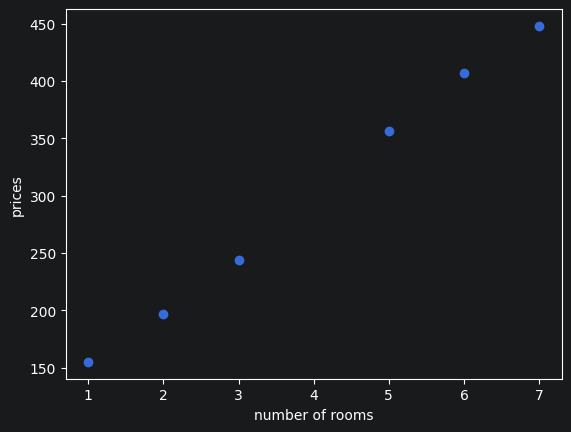

In [81]:
plot_points(features, labels)

Функция для определения ошибок

In [82]:
def simple_trick(base_price, price_per_room, num_rooms, price):
    small_random_1 = random.random()*0.1
    small_random_2 = random.random()*0.1
    predicted_price = base_price + price_per_room*num_rooms
    if price > predicted_price and num_rooms > 0:
        price_per_room += small_random_1
        base_price += small_random_2
    if price > predicted_price and num_rooms < 0:
        price_per_room -= small_random_1
        base_price += small_random_2
    if price < predicted_price and num_rooms > 0:
        price_per_room -= small_random_1
        base_price -= small_random_2
    if price < predicted_price and num_rooms < 0:
        price_per_room += small_random_1
        base_price -= small_random_2
    return price_per_room, base_price

In [83]:
def absolute_trick(base_price, price_per_room, num_rooms, price, learning_rate):
    predicted_price = base_price + price_per_room*num_rooms
    if price > predicted_price:
        price_per_room += learning_rate*num_rooms
        base_price += learning_rate
    else:
        price_per_room -= learning_rate*num_rooms
        base_price -= learning_rate
    return price_per_room, base_price

In [84]:
def square_trick(base_price, price_per_room, num_rooms, price, learning_rate):
    predicted_price = base_price + price_per_room*num_rooms
    price_per_room += learning_rate*num_rooms*(price-predicted_price)
    base_price += learning_rate*(price-predicted_price)
    return price_per_room, base_price

Запуск алгоритма линейной регрессии
Алгоритм линейной регрессии включает в себя:

Инициализацию случайными весами.

Многократное применение метода корректировки на основе квадратичной (или простой, или абсолютной) ошибки.

In [85]:
random.seed(0)
def linear_regression(features, labels, learning_rate=0.01, epochs = 10000):
    price_per_room = random.random()
    base_price = random.random()
    for epoch in range(epochs):
        # Раскомментируйте любую из следующих строк, чтобы построить графики для разных эпох
        #if epoch == 1:
        #if epoch <= 10:
        #if epoch <= 50:
        if epoch > 50:
        #if True:
            draw_line(price_per_room, base_price, starting=0, ending=8)
        i = random.randint(0, len(features)-1)
        num_rooms = features[i]
        price = labels[i]
        # Раскомментируйте, чтобы использовать другой вид ошибки
        #price_per_room, base_price = absolute_trick(base_price,
        price_per_room, base_price = square_trick(base_price,
                                                  price_per_room,
                                                  num_rooms,
                                                  price,
                                                  learning_rate=learning_rate)
    draw_line(price_per_room, base_price, 'black', starting=0, ending=8)
    plot_points(features, labels)
    print('Price per room:', price_per_room)
    print('Base price:', base_price)
    return price_per_room, base_price

Price per room: 51.05347808556453
Base price: 99.0970202799414


(np.float64(51.05347808556453), np.float64(99.0970202799414))

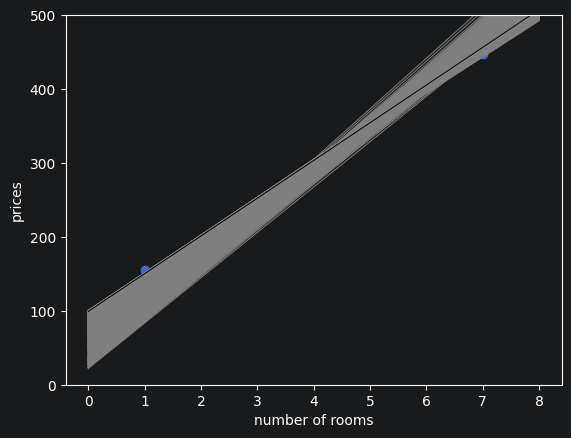

In [86]:
plt.ylim(0,500)
linear_regression(features, labels, learning_rate = 0.01, epochs = 10000)

Функция среднеквадратичной ошибки

In [87]:
def rmse(labels, predictions):
    n = len(labels)
    differences = np.subtract(labels, predictions)
    return np.sqrt(1.0/n * (np.dot(differences, differences)))

Построение графика функции ошибки

Price per room: 50.80146197445225
Base price: 100.0144049078708


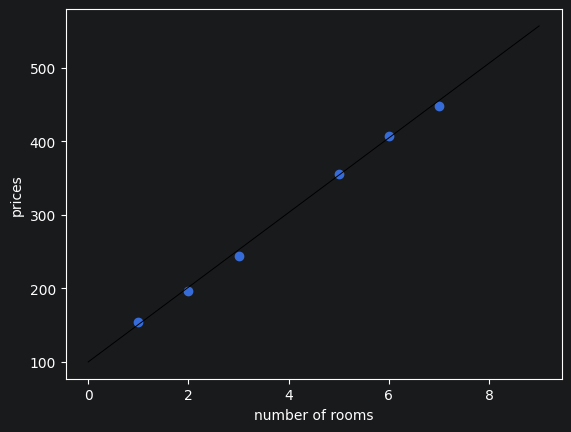

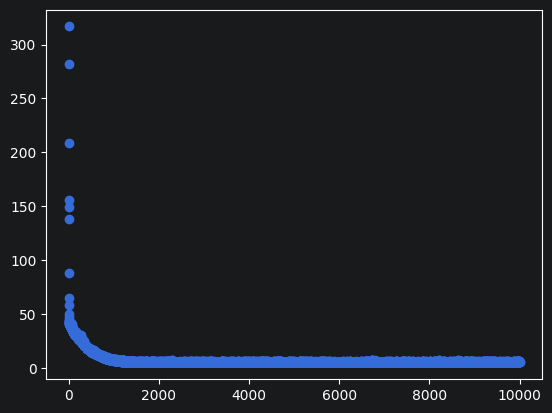

(np.float64(50.80146197445225), np.float64(100.0144049078708))

In [88]:
def linear_regression(features, labels, learning_rate=0.01, epochs = 10000):
    price_per_room = random.random()
    base_price = random.random()
    errors = []
    for i in range(epochs):
        predictions = features*price_per_room+base_price
        errors.append(rmse(labels, predictions))
        i = random.randint(0, len(features)-1)
        num_rooms = features[i]
        price = labels[i]
        # Uncomment one of the following 3 lines to use the simple, the absolute, or the square trick
        #price_per_room, base_price = simple_trick(base_price,
        #price_per_room, base_price = absolute_trick(base_price,
        price_per_room, base_price = square_trick(base_price,
                                                  price_per_room,
                                                  num_rooms,
                                                  price,
                                                  learning_rate=learning_rate)
    draw_line(price_per_room, base_price, 'black', starting=0, ending=9)
    plot_points(features, labels)
    print('Price per room:', price_per_room)
    print('Base price:', base_price)
    plt.show()
    plt.scatter(range(len(errors)), errors)
    plt.show()
    return price_per_room, base_price

linear_regression(features, labels, learning_rate = 0.01, epochs = 10000)

Линейная регрессия в Scikit-Learn

Coefficient: [50.39285714]
Intercept: 99.59523809523819
Predicted label for feature 4: [301.16666667]


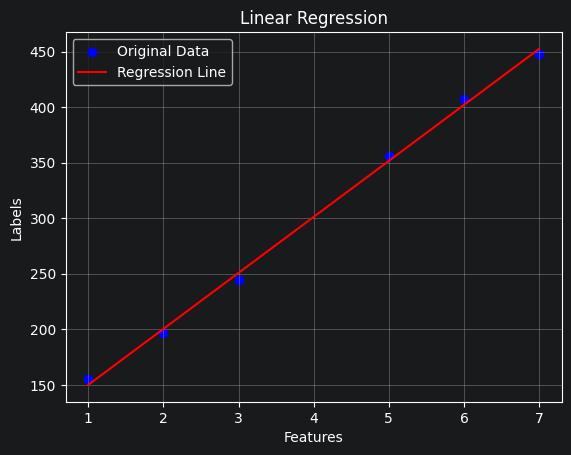

In [89]:
features_reshaped = features.reshape(-1, 1)
model = LinearRegression()
model.fit(features_reshaped, labels)
print("Coefficient:", model.coef_)
print("Intercept:", model.intercept_)
new_point = np.array([[4]])  # Predict for a feature value of 4
predicted_label = model.predict(new_point)
print("Predicted label for feature 4:", predicted_label)
predicted_labels = model.predict(features_reshaped)
plt.scatter(features, labels, color='blue', label='Original Data')
plt.plot(features, predicted_labels, color='red', label='Regression Line')
plt.xlabel('Features')
plt.ylabel('Labels')
plt.title('Linear Regression')
plt.legend()
plt.grid(True)
plt.show()